# 3. What helps: averaging reconstructions (posterior mean)

Notebook 2 found that the prior's errors sit **above the LR limit**, where the measurement says nothing, and that
giving the generator more freedom (IADrift) makes them larger. Two reconstructions of the same $y$ should then
**agree below $f_{\text{LR}}$** (both are pinned by $y$) and **disagree above it** (each invents its own detail).
Averaging several reconstructions keeps what they agree on and cancels what they invent. In Bayesian terms it
approximates the **posterior mean**, the estimator with the lowest expected squared error.

**Scope: test set (100 images), post-hoc addendum.** The ensemble was developed on development images after
the pre-registered test analysis of notebook 1. Its test run was then specified in `docs/PROTOCOL.md`, Section 11
(Addendum A), frozen, and signed off **before** any of its test runs existed. It is reported separately from the
pre-registered results.

**About the code cells.** They show the method in compact form; the code that produced the numbers is `scripts/test/run_ensemble_test.py` (the 300 shifted CSGM runs; driver
`bash scripts/test/run_overnight.sh ensemble`; library code `iadrift/ensemble.py`), `scripts/analysis/evaluate_test.py
--part ensemble` (members, weights, back-projection, metrics, primary tests) and
`scripts/analysis/export_ensemble_results.py` (the files in `results/`).

| Section | Content |
|---|---|
| 0 | Recap: what already helped in notebook 1 (back-projection, early stopping) |
| 1 | The posterior mean and the gain to expect from averaging |
| 2 | The ensemble members: restarts and shifted measurements |
| 3 | Weighting the members and back-projecting the average |
| 4 | Protocol (Addendum A) |
| 5 | **Results**: tables (PSNR, LPIPS) and figures |
| 6 | Summary |

## Setup

In [1]:
import json
import os
from pathlib import Path

os.environ.setdefault("JAX_PLATFORMS", "cpu")

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from jax.scipy.sparse.linalg import cg
from scipy import stats

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = REPO / "results"
sample = json.loads((RESULTS / "test_sample.json").read_text())
images = [s["image_index"] for s in sample]
base_metrics = json.loads((RESULTS / "test_metrics.json").read_text())       # notebook 1: bicubic, CSGM, IADrift
ens_metrics = json.loads((RESULTS / "ensemble_test_metrics.json").read_text())
primary_saved = json.loads((RESULTS / "ensemble_primary.json").read_text())
_ex, _ex1 = np.load(RESULTS / "ensemble_examples.npz"), np.load(RESULTS / "examples_test.npz")
ex = [{**{k.split("|", 1)[1]: _ex1[k].astype(np.float32) for k in _ex1.files if k.startswith(f"{n}|")},
       **{k.split("|", 1)[1]: _ex[k].astype(np.float32) for k in _ex.files if k.startswith(f"{n}|")}}
      for n in range(len(_ex["image_index"]))]

# Display name -> key in the result files.
KEY = {"bicubic + BP": "bicubic + BP", "CSGM + BP": "CSGM, correct label + BP",
       "E1 + BP": "E1: mean of 2 restarts + BP", "E2 + BP": "E2: mean of r0 + 3 shifts + BP",
       "Ens-U + BP": "Ens-U: mean of 5 CSGM runs + BP", "Ens-W + BP": "Ens-W: weighted 5 CSGM runs + BP",
       "IADrift @100 + BP": "IADrift @100, correct label + BP", "IADrift @1000 + BP": "IADrift @1000, correct label + BP",
       "bicubic": "bicubic", "CSGM": "CSGM, correct label", "IADrift @100": "IADrift @100, correct label",
       "IADrift @1000": "IADrift @1000, correct label"}
BANDS = ["low", "mid", "high", "very high"]


def per_image(method, key, band=None):
    k = KEY[method]
    src = ens_metrics if k in ens_metrics[str(images[0])] else base_metrics
    return np.array([src[str(i)][k]["band_snr_db"][band] if band else src[str(i)][k][key] for i in images])


def paired_stats(a, b, key):
    d = per_image(a, key) - per_image(b, key)
    lower_is_better = key in ("lpips", "blockiness")
    half = 1.96 * d.std(ddof=1) / np.sqrt(len(d))
    return {"mean": d.mean(), "lo": d.mean() - half, "hi": d.mean() + half, "p": stats.wilcoxon(d).pvalue,
            "better": int(np.sum(d < 0 if lower_is_better else d > 0)), "n": len(d)}


def holm(pvalues):
    order, adjusted, running = np.argsort(pvalues), np.empty(len(pvalues)), 0.0
    for rank, k in enumerate(order):
        running = max(running, min(1.0, (len(pvalues) - rank) * pvalues[k]))
        adjusted[k] = running
    return adjusted


def mean_ci(v):
    return np.mean(v), stats.t.ppf(0.975, len(v) - 1) * np.std(v, ddof=1) / np.sqrt(len(v))


def psnr_of_mean_mse(psnrs):
    return float(-10 * np.log10(np.mean(10 ** (-np.asarray(psnrs) / 10))))


show = lambda x: (np.clip(x, -1, 1) + 1) / 2
print(f"{len(images)} test images; ensemble results for {len(ens_metrics)}; {len(ex)} example images")

100 test images; ensemble results for 100; 4 example images


## 0. Recap: what already helped in notebook 1 (test set, pre-registered)

Two parameter-free steps from notebook 1 already moved the results in the right direction. Recomputed here from the
same per-image results (differences on the 100 test images, correct label).

In [2]:
rows = [("Back-projection on CSGM", "CSGM + BP", "CSGM"), ("Back-projection on bicubic", "bicubic + BP", "bicubic"),
        ("Early stopping of IADrift (step 100 vs 1,000), + BP", "IADrift @100 + BP", "IADrift @1000 + BP")]
lines = ["| What helped | Comparison | PSNR gain (dB) | better on | LPIPS change | better on |", "|---|---|---:|---:|---:|---:|"]
for name, a, b in rows:
    rp, rl = paired_stats(a, b, "psnr"), paired_stats(a, b, "lpips")
    lines.append(f"| {name} | {a} − {b} | {rp['mean']:+.2f} | {rp['better']}/100 | {rl['mean']:+.3f} | {rl['better']}/100 |")
display(Markdown("**Table 11. Already shown in notebook 1** (pre-registered test analysis)\n\n" + "\n".join(lines)))

**Table 11. Already shown in notebook 1** (pre-registered test analysis)

| What helped | Comparison | PSNR gain (dB) | better on | LPIPS change | better on |
|---|---|---:|---:|---:|---:|
| Back-projection on CSGM | CSGM + BP − CSGM | +1.05 | 100/100 | -0.080 | 100/100 |
| Back-projection on bicubic | bicubic + BP − bicubic | +0.56 | 100/100 | -0.054 | 100/100 |
| Early stopping of IADrift (step 100 vs 1,000), + BP | IADrift @100 + BP − IADrift @1000 + BP | +2.80 | 100/100 | -0.090 | 92/100 |

Back-projection removes what contradicts the measurement; early stopping limits how much invented detail
adaptation adds. Neither removes the wrong detail the prior has already put above $f_{\text{LR}}$. Averaging does.

## 1. The posterior mean, and how much averaging should help

Among all estimators of $x^\star$ from $y$, the **posterior mean** $\mu = \mathbb E[x \mid y]$ has the lowest expected
squared error, the MMSE: $\ \mathbb E\|\mu - x^\star\|^2 = \operatorname{tr}\Sigma$, with $\Sigma = \operatorname{Cov}(x \mid y)$.

If we model each reconstruction as an independent **sample** from the posterior, $x_k = \mu + u_k$, with the truth
$x^\star = \mu + u^\star$ and all deviations independent with zero mean and covariance $\Sigma$, then

$$
\mathbb E\|x_k - x^\star\|^2 = 2\operatorname{tr}\Sigma = 2\,\text{MMSE},
\qquad
\mathbb E\Big\|\tfrac1K\textstyle\sum_{k=1}^K x_k - x^\star\Big\|^2 = \big(1 + \tfrac1K\big)\,\text{MMSE}.
$$

So averaging $K$ samples reduces the error by a factor $\frac{2}{1 + 1/K}$, i.e. a PSNR gain of

$$
\Delta\text{PSNR} = 10\log_{10}\frac{2}{1 + 1/K} \quad\Rightarrow\quad K = 5:\ \ 10\log_{10}\frac{2}{1.2} = 2.22 \text{ dB}.
$$

Caveats: CSGM is not exact posterior sampling (it is a local fit), and the members share the generator and partly
their starting point, so they are not independent. The prediction is a reference point, not a guarantee.

In [3]:
for K in (1, 2, 4, 5, 10, 1000):
    print(f"K = {K:4d}: predicted PSNR gain of the mean of K posterior samples = {10 * np.log10(2 / (1 + 1 / K)):.2f} dB")

K =    1: predicted PSNR gain of the mean of K posterior samples = 0.00 dB
K =    2: predicted PSNR gain of the mean of K posterior samples = 1.25 dB
K =    4: predicted PSNR gain of the mean of K posterior samples = 2.04 dB
K =    5: predicted PSNR gain of the mean of K posterior samples = 2.22 dB
K =   10: predicted PSNR gain of the mean of K posterior samples = 2.60 dB
K = 1000: predicted PSNR gain of the mean of K posterior samples = 3.01 dB


## 2. The members: restarts and shifted measurements

For each test image we use **5 CSGM reconstructions** (correct label), each run exactly as in notebook 1
(Adam lr 0.02, 5,000 steps, no regularizer):

- **2 restarts** $r_0, r_1$: different random starts $(\varepsilon, z)$. These are the two CSGM runs of notebook 1;
  CSGM itself keeps only the one with the lower LR loss.
- **3 shifted runs**: CSGM on the measurement circularly shifted by $s \in \{(0,1), (1,0), (1,1)\}$ LR pixels, starting
  from the $r_0$ start, with the output shifted back by $4s$ HR pixels:

$$
x_s = S_{-4s}\,\text{CSGM}(S_s\, y), \qquad S_s = \text{circular shift by } s .
$$

Shifting by 4 HR pixels commutes with $A$ (up to the image border), so $x_s$ is still consistent with $y$. But the
generator sees the scene moved relative to its **16-pixel patch grid**, so it invents different detail and puts its
tile seams in different places: a cheap source of diversity.

In [4]:
SHIFTS = [(0, 1), (1, 0), (1, 1)]


def shifted_member(csgm_fn, y, sy, sx):
    """One shifted member: CSGM on y rolled by (sy, sx) LR pixels, output rolled back by 4x that. y: [64, 64, 3]."""
    x = csgm_fn(np.roll(y, (sy, sx), axis=(0, 1)))
    return np.roll(x, (-4 * sy, -4 * sx), axis=(0, 1))
# The 300 shifted test runs: scripts/test/run_ensemble_test.py (iadrift.ensemble.shift_y / unshift_x; bit-exact with notebook 1's CSGM).

**Figure 13** shows the 5 members of the first test image and their plain average. Look at the detail crops:
the members disagree in texture and seams; the average keeps the shared structure and smooths the disagreements.

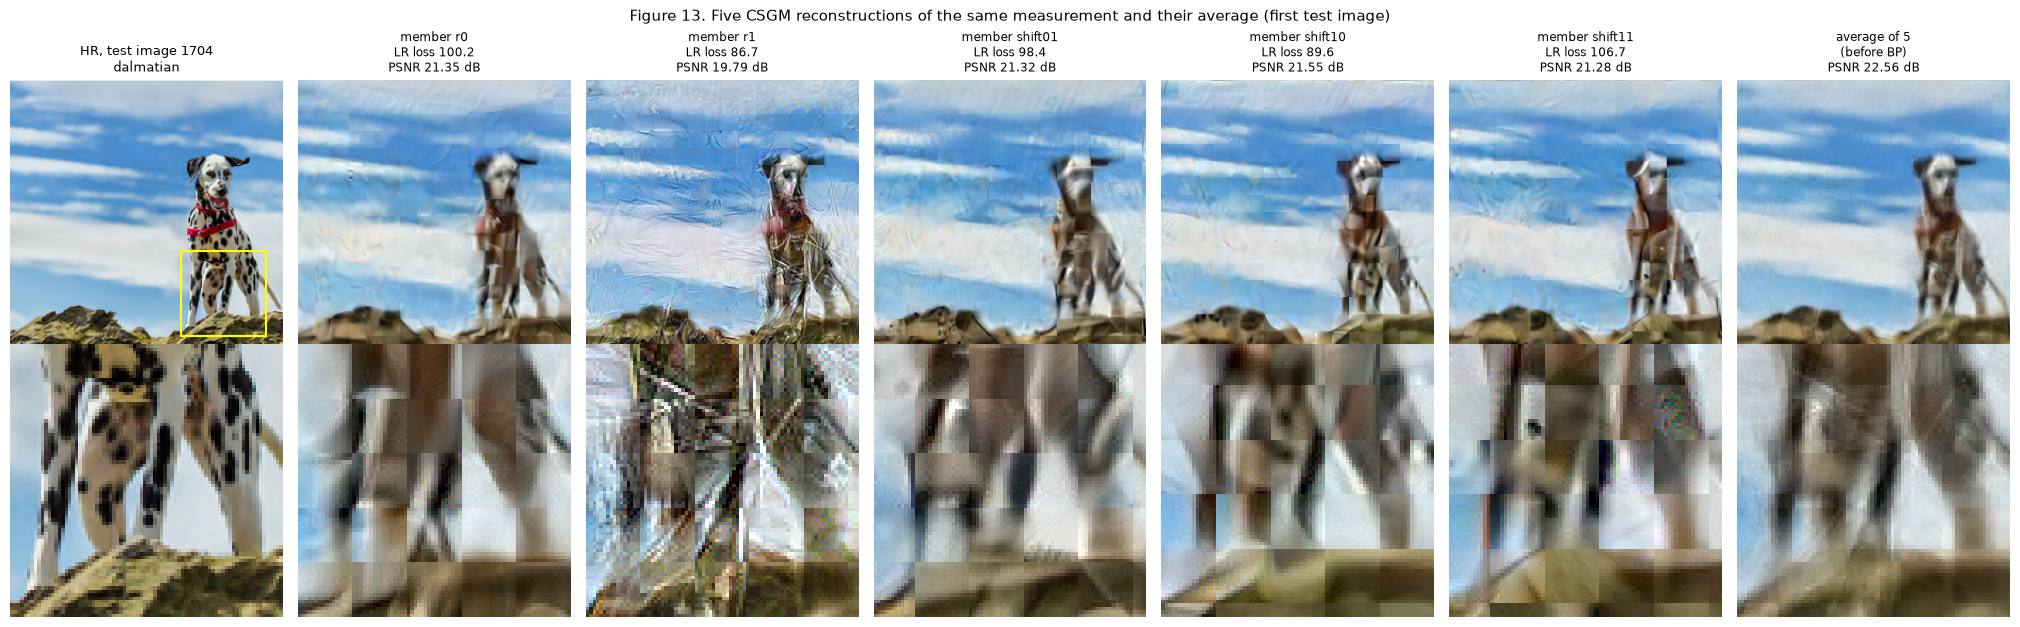

In [5]:
CROP = 80


def detail_crop(hr):
    g = np.abs(np.diff(hr.mean(-1), axis=0))[:, :-1] + np.abs(np.diff(hr.mean(-1), axis=1))[:-1, :]
    pos = [(r, c) for r in range(0, 256 - CROP, 16) for c in range(0, 256 - CROP, 16)]
    return max(pos, key=lambda p: g[p[0]:p[0] + CROP, p[1]:p[1] + CROP].sum())


MEMBERS = ["r0", "r1", "shift01", "shift10", "shift11"]
e, i = ex[0], images[0]
info = ens_metrics[str(i)]["info"]
mean5 = np.mean([e[m] for m in MEMBERS], axis=0)
psnr = lambda x: -10 * np.log10(np.mean(((x - e["hr"]) / 2) ** 2))
panels = [(f"member {m}\nLR loss {info['L'][m]:.1f}", e[m]) for m in MEMBERS] + [("average of 5\n(before BP)", mean5)]
r, c = detail_crop(e["hr"])
fig, axes = plt.subplots(2, len(panels) + 1, figsize=(2.9 * (len(panels) + 1), 6.4))
axes[0, 0].imshow(show(e["hr"]))
axes[0, 0].add_patch(plt.Rectangle((c, r), CROP, CROP, fill=False, color="yellow", lw=1.5))
axes[0, 0].set_title(f"HR, test image {i}\n{sample[0]['true_class']}", fontsize=9)
axes[1, 0].imshow(show(e["hr"][r:r + CROP, c:c + CROP]), interpolation="nearest")
for k, (name, x) in enumerate(panels, start=1):
    axes[0, k].imshow(show(x))
    axes[0, k].set_title(f"{name}\nPSNR {psnr(x):.2f} dB", fontsize=8.5)
    axes[1, k].imshow(show(x[r:r + CROP, c:c + CROP]), interpolation="nearest")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Figure 13. Five CSGM reconstructions of the same measurement and their average (first test image)", fontsize=11)
plt.tight_layout()
plt.show()

## 3. Weighting the members, then back-projection

A member that fits $y$ badly can drag the average towards wrong content (ghosting). The **weighted** ensemble down-weights
such members using only the LR loss $L_k = \|y - A x_k\|^2$ (never the HR image):

$$
w_k = \frac{\exp\!\big(-(L_k - L_{\min})/T\big)}{\sum_j \exp\!\big(-(L_j - L_{\min})/T\big)}, \qquad T = \operatorname{std}(L_1, \dots, L_K),
\qquad \hat x = \mathrm{BP}\Big(\sum_k w_k x_k\Big).
$$

The temperature $T$ adapts to each image: members within about one standard deviation of the best get comparable
weight. The ensembles compared (all followed by back-projection, Section 6 of notebook 1):

| Ensemble | Members | Weights | Role |
|---|---|---|---|
| **Ens-W** | all 5 | LR-loss weights | **primary** (pre-declared) |
| Ens-U | all 5 | uniform | secondary |
| E1 | $r_0, r_1$ | uniform | secondary: restarts only |
| E2 | $r_0$ + 3 shifts | uniform | secondary: shifts only |

In [6]:
_A_transpose = jax.linear_transpose(lambda x: jax.image.resize(x, (1, 64, 64, 3), method="cubic", antialias=True),
                                    jnp.zeros((1, 256, 256, 3), jnp.float32))
A_sr4 = lambda x: jax.image.resize(x.astype(jnp.float32), (x.shape[0], 64, 64, 3), method="cubic", antialias=True)


@jax.jit
def _backproject(x, y):
    AT = lambda v: _A_transpose(v)[0]
    u, _ = cg(lambda v: A_sr4(AT(v)), y - A_sr4(x), tol=1e-6, maxiter=500)
    return x + AT(u)


def backproject(x, y):
    return np.asarray(_backproject(jnp.asarray(x, jnp.float32)[None], jnp.asarray(y, jnp.float32)[None])[0])


def ensemble(members, lr_losses, y, weighted):
    """members: list of [256, 256, 3]; lr_losses: their ||y - A x_k||^2. Returns (BP of the (weighted) mean, weights)."""
    L = np.asarray(lr_losses, np.float64)
    w = np.exp(-(L - L.min()) / max(L.std(), 1e-6)) if weighted else np.ones(len(L))
    w = w / w.sum()
    return backproject(sum(wk * x for wk, x in zip(w, members)), y), w


# Check: rebuild Ens-W + BP for the first test image from its stored members and LR losses.
x_ens_w, w = ensemble([e[m] for m in MEMBERS], [info["L"][m] for m in MEMBERS], e["lr"], weighted=True)
print("weights:", dict(zip(MEMBERS, np.round(w, 3))), "| effective number of members 1/Σw² =", round(1 / np.sum(w ** 2), 2))
print(f"max |rebuilt Ens-W + BP - stored| = {np.abs(x_ens_w - e['Ens-W + BP']).max():.1e} (float16 storage of the example arrays)")

weights: {'r0': 0.074, 'r1': 0.479, 'shift01': 0.095, 'shift10': 0.32, 'shift11': 0.031} | effective number of members 1/Σw² = 2.88
max |rebuilt Ens-W + BP - stored| = 8.2e-04 (float16 storage of the example arrays)


## 4. Protocol (Addendum A, `docs/PROTOCOL.md`, Section 11)

- **Frozen before the run:** the 100 test images and correct label of notebook 1; the members and the weighting rule
  above; Ens-W as the primary method; the analysis below. Signed off 2026-10-06; runner settings hash `ca2d0ec5e6ff`.
- **Reproducibility check before launch:** the runner reproduced a saved CSGM test run and a development shifted run
  bit-exactly.
- **Primary tests (Holm over 2):** Ens-W + BP vs CSGM + BP on PSNR and on LPIPS, paired over the 100 images (same
  statistics as notebook 1). Everything else is **exploratory** (uncorrected).
- **Disclosure:** the first launch was killed by the operating system after 2 saved runs (out of memory, caused by a
  second process); it resumed with identical settings, and the 2 saved runs were kept (they are deterministic).

## 5. Results (100 test images, correct label)

### 5.1 Main table

In [7]:
METHODS = ["bicubic + BP", "CSGM + BP", "E1 + BP", "E2 + BP", "Ens-U + BP", "Ens-W + BP"]
RUNS = {"bicubic + BP": 0, "CSGM + BP": 1, "E1 + BP": 2, "E2 + BP": 4, "Ens-U + BP": 5, "Ens-W + BP": 5}
rows = [(m, per_image(m, "psnr").mean(), psnr_of_mean_mse(per_image(m, "psnr")), per_image(m, "lpips").mean(),
         per_image(m, "blockiness").mean()) for m in METHODS]
best = {1: max(r[1] for r in rows), 2: max(r[2] for r in rows), 3: min(r[3] for r in rows)}
fmt = lambda k, v, f: f"**{v:{f}}**" if k in best and np.isclose(v, best[k]) else f"{v:{f}}"
lines = ["| Method | CSGM runs | PSNR (dB) ↑ | PSNR of mean MSE (dB) ↑ | LPIPS ↓ | Blockiness (HR 1.01) |", "|---|---:|---:|---:|---:|---:|"]
lines += [f"| {r[0]} | {RUNS[r[0]]} | {fmt(1, r[1], '.2f')} | {fmt(2, r[2], '.2f')} | {fmt(3, r[3], '.3f')} | {r[4]:.2f} |" for r in rows]
display(Markdown("**Table 12. Posterior-mean ensembles on 100 test images, correct label** (all + BP)\n\n" + "\n".join(lines)))
n_eff = np.array([ens_metrics[str(i)]["info"]["Ens-W: weighted 5 CSGM runs"]["n_eff"] for i in images])
print(f"Ens-W: effective number of members 1/Σw² = {n_eff.mean():.2f} on average (range {n_eff.min():.2f}-{n_eff.max():.2f}) of 5")

**Table 12. Posterior-mean ensembles on 100 test images, correct label** (all + BP)

| Method | CSGM runs | PSNR (dB) ↑ | PSNR of mean MSE (dB) ↑ | LPIPS ↓ | Blockiness (HR 1.01) |
|---|---:|---:|---:|---:|---:|
| bicubic + BP | 0 | **25.57** | **24.14** | 0.358 | 1.01 |
| CSGM + BP | 1 | 22.75 | 21.66 | 0.284 | 1.26 |
| E1 + BP | 2 | 23.76 | 22.58 | 0.259 | 1.23 |
| E2 + BP | 4 | 24.69 | 23.46 | 0.253 | 1.14 |
| Ens-U + BP | 5 | 24.88 | 23.62 | **0.247** | 1.17 |
| Ens-W + BP | 5 | 24.32 | 23.13 | 0.252 | 1.21 |

Ens-W: effective number of members 1/Σw² = 2.90 on average (range 1.73-4.16) of 5


### 5.2 Primary tests (Addendum A)

In [8]:
PRIMARY = [("Ens-W + BP", "CSGM + BP", key) for key in ("psnr", "lpips")]
res = [paired_stats(a, b, key) for a, b, key in PRIMARY]
adj = holm(np.array([r["p"] for r in res]))
for r, pa, saved in zip(res, adj, primary_saved):
    assert np.isclose(r["mean"], saved["mean"]) and np.isclose(pa, saved["holm_p"]), "differs from the saved analysis"
lines = ["| Comparison | Metric | Mean difference | 95% CI | Holm-corrected p | Ens-W better on |", "|---|---|---:|---:|---:|---:|"]
for (a, b, key), r, pa in zip(PRIMARY, res, adj):
    f = "{:+.3f}" if key == "lpips" else "{:+.2f}"
    lines.append(f"| {a} − {b} | {'LPIPS ↓' if key == 'lpips' else 'PSNR (dB)'} | {f.format(r['mean'])} | "
                 f"[{f.format(r['lo'])}, {f.format(r['hi'])}] | {pa:.1e} | {r['better']}/{r['n']} images |")
display(Markdown("**Table 13. Primary tests (Holm over 2).** Both significant.\n\n" + "\n".join(lines)))

lines = ["| A − B | PSNR (dB) | 95% CI | better | LPIPS | 95% CI | better |", "|---|---:|---:|---:|---:|---:|---:|"]
for a, b in [("E1 + BP", "CSGM + BP"), ("E2 + BP", "CSGM + BP"), ("Ens-U + BP", "CSGM + BP"), ("Ens-W + BP", "Ens-U + BP"),
             ("Ens-U + BP", "bicubic + BP"), ("Ens-W + BP", "bicubic + BP"), ("Ens-U + BP", "IADrift @100 + BP")]:
    rp, rl = paired_stats(a, b, "psnr"), paired_stats(a, b, "lpips")
    lines.append(f"| {a} − {b} | {rp['mean']:+.2f} | [{rp['lo']:+.2f}, {rp['hi']:+.2f}] | {rp['better']}/100 | "
                 f"{rl['mean']:+.3f} | [{rl['lo']:+.3f}, {rl['hi']:+.3f}] | {rl['better']}/100 |")
display(Markdown("**Table 14. Secondary comparisons** (exploratory, uncorrected)\n\n" + "\n".join(lines)))

**Table 13. Primary tests (Holm over 2).** Both significant.

| Comparison | Metric | Mean difference | 95% CI | Holm-corrected p | Ens-W better on |
|---|---|---:|---:|---:|---:|
| Ens-W + BP − CSGM + BP | PSNR (dB) | +1.57 | [+1.40, +1.74] | 7.8e-18 | 100/100 images |
| Ens-W + BP − CSGM + BP | LPIPS ↓ | -0.032 | [-0.040, -0.024] | 5.7e-10 | 76/100 images |

**Table 14. Secondary comparisons** (exploratory, uncorrected)

| A − B | PSNR (dB) | 95% CI | better | LPIPS | 95% CI | better |
|---|---:|---:|---:|---:|---:|---:|
| E1 + BP − CSGM + BP | +1.01 | [+0.84, +1.19] | 89/100 | -0.025 | [-0.034, -0.015] | 67/100 |
| E2 + BP − CSGM + BP | +1.94 | [+1.70, +2.18] | 98/100 | -0.031 | [-0.045, -0.017] | 63/100 |
| Ens-U + BP − CSGM + BP | +2.13 | [+1.89, +2.37] | 100/100 | -0.037 | [-0.051, -0.023] | 65/100 |
| Ens-W + BP − Ens-U + BP | -0.56 | [-0.68, -0.44] | 10/100 | +0.005 | [-0.002, +0.012] | 53/100 |
| Ens-U + BP − bicubic + BP | -0.69 | [-0.84, -0.55] | 11/100 | -0.111 | [-0.126, -0.096] | 92/100 |
| Ens-W + BP − bicubic + BP | -1.25 | [-1.47, -1.02] | 5/100 | -0.106 | [-0.125, -0.087] | 85/100 |
| Ens-U + BP − IADrift @100 + BP | +2.25 | [+2.03, +2.47] | 100/100 | -0.029 | [-0.042, -0.015] | 60/100 |

### 5.3 Figures

**Figure 14**: every method of notebooks 1 and 3 in the PSNR–LPIPS plane (mean ± 95% CI, all + BP). **Figure 15**: the
primary comparison image by image. **Figure 16**: the gain grows with the number of members.

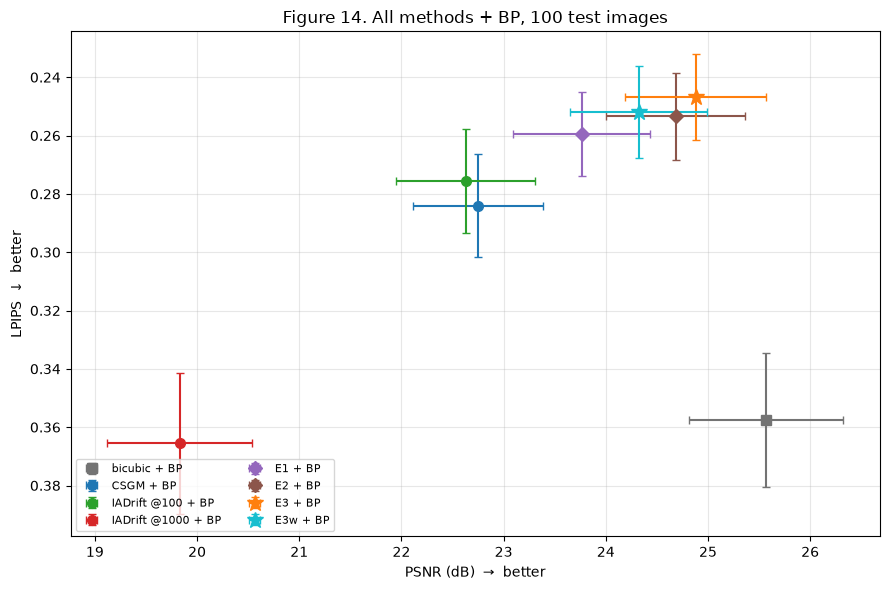

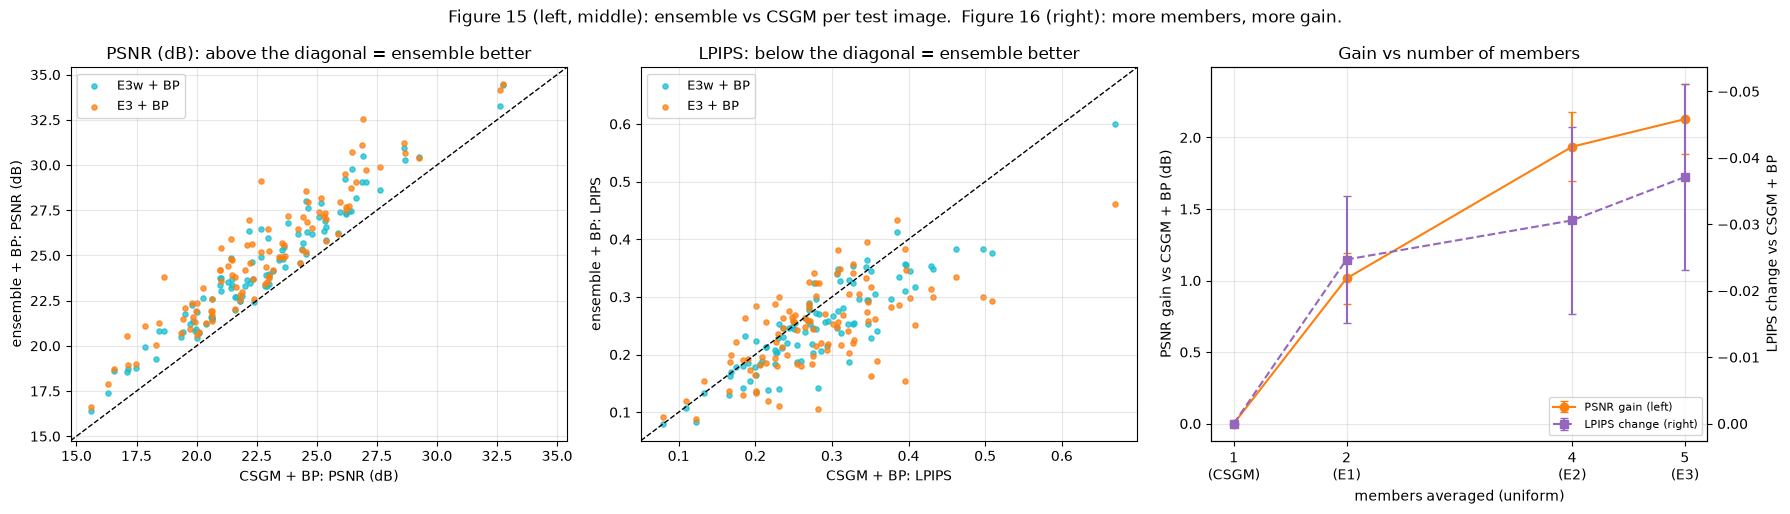

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
STYLE = {"bicubic + BP": ("0.45", "s"), "CSGM + BP": ("C0", "o"), "IADrift @100 + BP": ("C2", "o"),
         "IADrift @1000 + BP": ("C3", "o"), "E1 + BP": ("C4", "D"), "E2 + BP": ("C5", "D"), "Ens-U + BP": ("C1", "*"),
         "Ens-W + BP": ("C9", "*")}
for m, (color, marker) in STYLE.items():
    (px, ex_), (ly, ey) = mean_ci(per_image(m, "psnr")), mean_ci(per_image(m, "lpips"))
    ax.errorbar(px, ly, xerr=ex_, yerr=ey, fmt=marker, color=color, ms=12 if marker == "*" else 7, capsize=3, label=m)
ax.set(xlabel="PSNR (dB)  →  better", ylabel="LPIPS  ↓  better", title="Figure 14. All methods + BP, 100 test images")
ax.invert_yaxis()
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=2, loc="lower left")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for ax, key, title in ((axes[0], "psnr", "PSNR (dB)"), (axes[1], "lpips", "LPIPS")):
    ref = per_image("CSGM + BP", key)
    for m, color in (("Ens-W + BP", "C9"), ("Ens-U + BP", "C1")):
        ax.scatter(ref, per_image(m, key), s=14, alpha=0.75, color=color, label=m)
    lo, hi = min(ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel=f"CSGM + BP: {title}", ylabel=f"ensemble + BP: {title}",
           title=f"{title}: " + ("above the diagonal = ensemble better" if key == "psnr" else "below the diagonal = ensemble better"))
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)
counts, names = [1, 2, 4, 5], ["CSGM + BP", "E1 + BP", "E2 + BP", "Ens-U + BP"]
ref_p, ref_l = per_image("CSGM + BP", "psnr"), per_image("CSGM + BP", "lpips")
gp = [mean_ci(per_image(n, "psnr") - ref_p) for n in names]
ax2 = axes[2].twinx()
axes[2].errorbar(counts, [g[0] for g in gp], yerr=[g[1] for g in gp], marker="o", color="C1", capsize=3, label="PSNR gain (left)")
gl = [mean_ci(per_image(n, "lpips") - ref_l) for n in names]
ax2.errorbar(counts, [g[0] for g in gl], yerr=[g[1] for g in gl], marker="s", ls="--", color="C4", capsize=3, label="LPIPS change (right)")
axes[2].set(xticks=counts, xticklabels=["1\n(CSGM)", "2\n(E1)", "4\n(E2)", "5\n(Ens-U)"], xlabel="members averaged (uniform)",
            ylabel="PSNR gain vs CSGM + BP (dB)", title="Gain vs number of members")
ax2.set_ylabel("LPIPS change vs CSGM + BP")
ax2.invert_yaxis()
h1, l1 = axes[2].get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
axes[2].legend(h1 + h2, l1 + l2, fontsize=8, loc="lower right")
axes[2].grid(alpha=0.3)
fig.suptitle("Figure 15 (left, middle): ensemble vs CSGM per test image.  Figure 16 (right): more members, more gain.", fontsize=12)
plt.tight_layout()
plt.show()

### 5.4 Does the gain match the posterior-mean prediction?

For each test image: the members' mean squared error divided by the error of their uniform average (Ens-U), **before**
back-projection, in dB, compared with the $2.22$ dB predicted in Section 1 for independent posterior samples.

**MMSE check (Ens-U, before BP):** measured gain **2.33 dB** [95% CI 2.18, 2.48], median 2.28, range 1.00 to 4.78; prediction for 5 independent posterior samples **2.22 dB**.

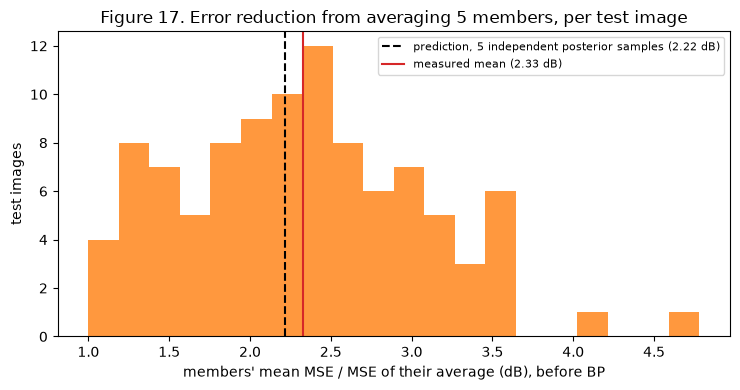

In [10]:
gain = np.array([10 * np.log10(np.mean(list(ens_metrics[str(i)]["info"]["member_mse"].values()))
                                / ens_metrics[str(i)]["info"]["Ens-U: mean of 5 CSGM runs"]["mse_raw"]) for i in images])
m, h = mean_ci(gain)
display(Markdown(f"**MMSE check (Ens-U, before BP):** measured gain **{m:.2f} dB** [95% CI {m - h:.2f}, {m + h:.2f}], median "
                 f"{np.median(gain):.2f}, range {gain.min():.2f} to {gain.max():.2f}; prediction for 5 independent posterior samples "
                 f"**{10 * np.log10(2 / 1.2):.2f} dB**."))
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.hist(gain, bins=20, color="C1", alpha=0.8)
ax.axvline(10 * np.log10(2 / 1.2), color="k", ls="--", label="prediction, 5 independent posterior samples (2.22 dB)")
ax.axvline(m, color="C3", label=f"measured mean ({m:.2f} dB)")
ax.set(xlabel="members' mean MSE / MSE of their average (dB), before BP", ylabel="test images",
       title="Figure 17. Error reduction from averaging 5 members, per test image")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 5.5 Where the gain comes from: frequency bands and tile seams

In [11]:
SHOW = ["bicubic + BP", "CSGM + BP", "E1 + BP", "E2 + BP", "Ens-U + BP", "Ens-W + BP"]
lines = ["| Method | low | mid | **high** | **very high** | blockiness |", "|---|---:|---:|---:|---:|---:|"]
for s in SHOW:
    lines.append(f"| {s} | " + " | ".join(f"{per_image(s, None, b).mean():+.2f}" for b in BANDS)
                 + f" | {per_image(s, 'blockiness').mean():.2f} |")
display(Markdown("**Table 15. Band SNR (dB) and blockiness, 100 test images.** Bands above the LR limit in bold.\n\n" + "\n".join(lines)))

**Table 15. Band SNR (dB) and blockiness, 100 test images.** Bands above the LR limit in bold.

| Method | low | mid | **high** | **very high** | blockiness |
|---|---:|---:|---:|---:|---:|
| bicubic + BP | +57.19 | +14.39 | +0.68 | -0.00 | 1.01 |
| CSGM + BP | +54.49 | +13.29 | -1.04 | -4.07 | 1.26 |
| E1 + BP | +55.40 | +14.08 | -0.27 | -3.07 | 1.23 |
| E2 + BP | +56.30 | +14.83 | +0.51 | -1.74 | 1.14 |
| Ens-U + BP | +56.50 | +14.95 | +0.62 | -1.56 | 1.17 |
| Ens-W + BP | +56.04 | +14.57 | +0.22 | -2.25 | 1.21 |

Averaging improves every band by 1.7 to 2.5 dB, below the LR limit as well as above it, with the largest gain in the
very-high band. Above the limit it lifts single reconstructions that were worse than nothing (Ens-U vs CSGM: high
−1.04 → +0.62 dB, very high −4.07 → −1.56 dB). The very-high band stays below
0 dB, so some invented detail remains; this is why bicubic + BP keeps the PSNR lead. Members from shifted measurements
(E2) reduce the tile seams more than restarts (E1), as expected: their seams fall in different places and average out.

### 5.6 Visual examples

The first 4 images of the fixed test sample (not chosen by result), with an $80\times80$ detail crop. Titles: PSNR / LPIPS.

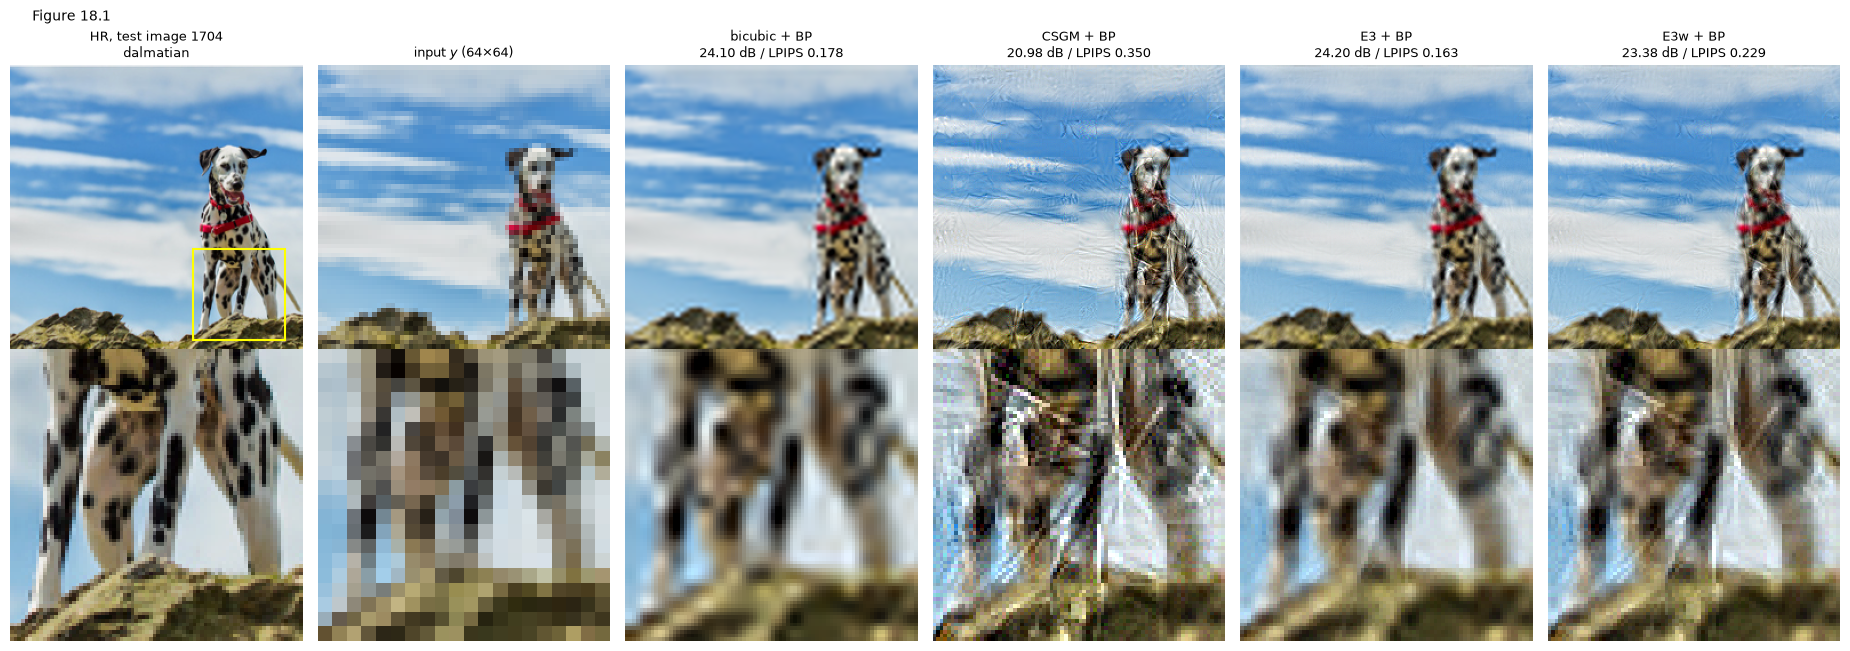

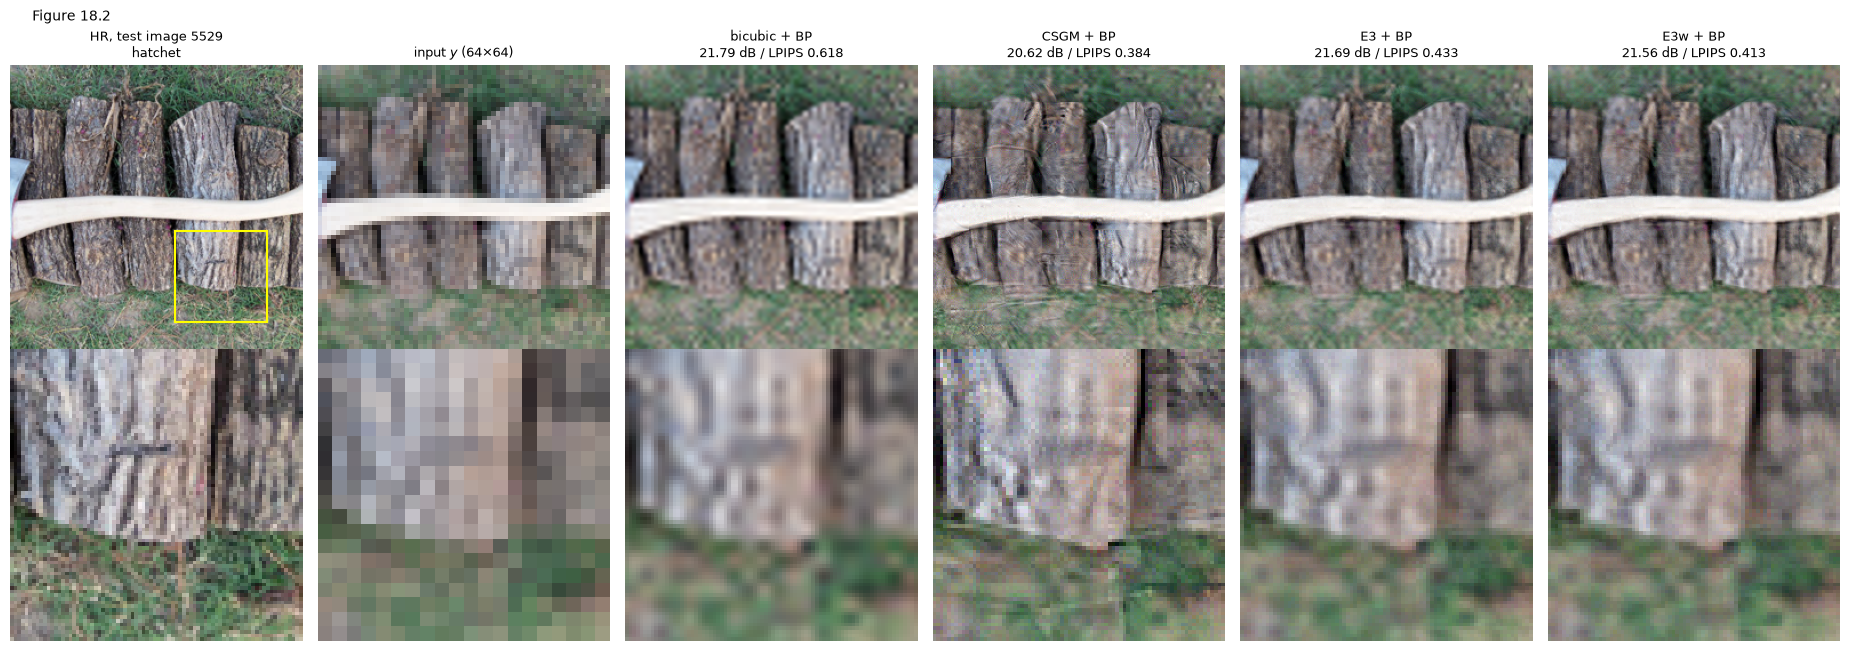

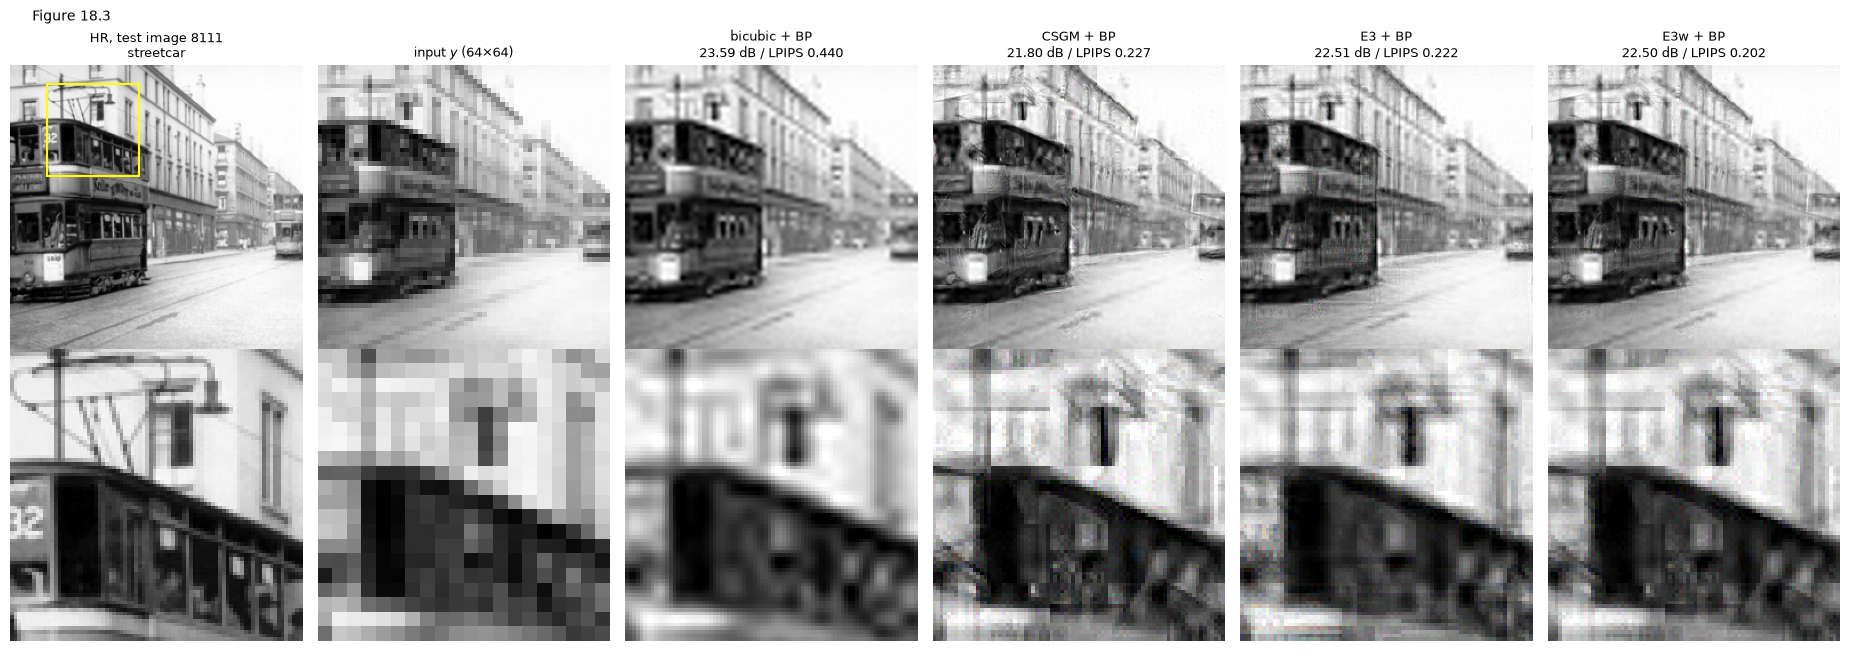

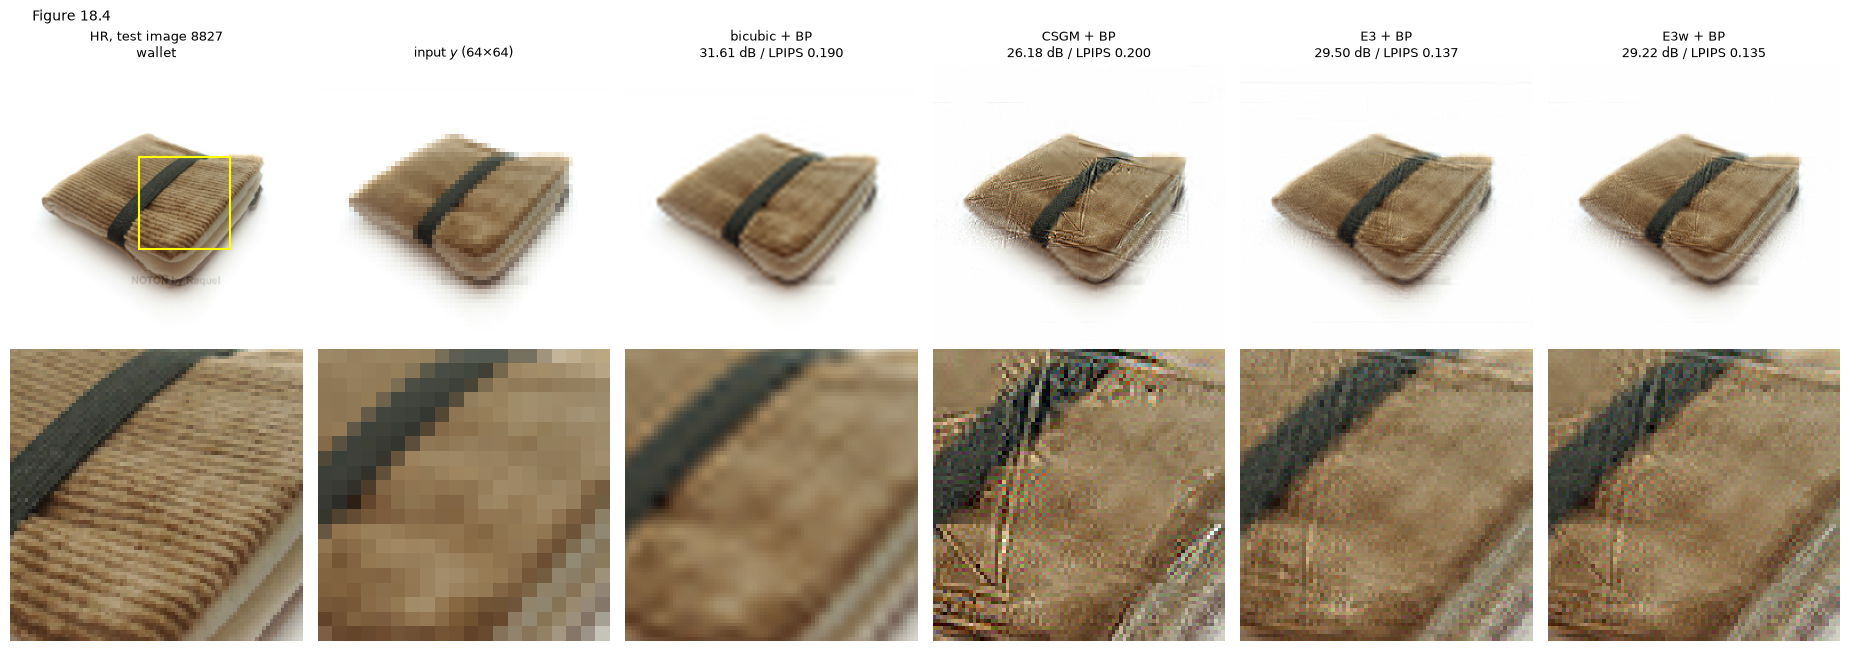

In [12]:
PANELS = ["bicubic + BP", "CSGM + BP", "Ens-U + BP", "Ens-W + BP"]
EXKEY = {"bicubic + BP": "bicubic + BP", "CSGM + BP": "CSGM, correct label + BP", "Ens-U + BP": "Ens-U + BP", "Ens-W + BP": "Ens-W + BP"}
for n, e in enumerate(ex):
    i, hr = images[n], e["hr"]
    r, c = detail_crop(hr)
    fig, axes = plt.subplots(2, len(PANELS) + 2, figsize=(3.1 * (len(PANELS) + 2), 6.6))
    axes[0, 0].imshow(show(hr))
    axes[0, 0].add_patch(plt.Rectangle((c, r), CROP, CROP, fill=False, color="yellow", lw=1.5))
    axes[0, 0].set_title(f"HR, test image {i}\n{sample[n]['true_class']}", fontsize=9)
    axes[1, 0].imshow(show(hr[r:r + CROP, c:c + CROP]), interpolation="nearest")
    axes[0, 1].imshow(show(e["lr"]), interpolation="nearest")
    axes[0, 1].set_title("input $y$ (64×64)", fontsize=9)
    axes[1, 1].imshow(show(e["lr"][r // 4:(r + CROP) // 4, c // 4:(c + CROP) // 4]), interpolation="nearest")
    for k, m in enumerate(PANELS, start=2):
        x, mm = e[EXKEY[m]], {"psnr": per_image(m, "psnr")[n], "lpips": per_image(m, "lpips")[n]}
        axes[0, k].imshow(show(x))
        axes[0, k].set_title(f"{m}\n{mm['psnr']:.2f} dB / LPIPS {mm['lpips']:.3f}", fontsize=9)
        axes[1, k].imshow(show(x[r:r + CROP, c:c + CROP]), interpolation="nearest")
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(f"Figure 18.{n + 1}", fontsize=10, x=0.02, ha="left")
    plt.tight_layout()
    plt.show()

## 6. Summary

1. **Averaging works on the test set.** The pre-declared weighted ensemble Ens-W + BP beats CSGM + BP by
   **+1.57 dB on all 100 images** and improves LPIPS by 0.032 (76/100); both primary tests are significant after Holm
   correction (Tables 12–13). The development result (6 images: +1.60 dB / −0.029) is confirmed.
2. **The uniform average does better on PSNR.** Ens-U + BP gains +2.13 dB (100/100) with LPIPS −0.037. Ens-W stays the
   primary result because it was declared before the run; Ens-U is exploratory. Down-weighting by LR loss guards against
   ghosting from a badly fitting member, but on average it throws away diversity (Ens-W uses about 2.9 of 5 members).
3. **The gain is close to the posterior-mean prediction.** Averaging 5 members lowers the error before BP by 2.33 dB
   (mean of the per-image gains, Figure 17), or 2.14 dB from the MSE pooled over images, against the 2.22 dB predicted
   for independent posterior samples. The gain grows with the number of members (Figure 16), and every frequency band
   improves, by 1.7 to 2.5 dB (Table 15).
4. **Best perceptual quality of all methods.** Every ensemble has a better LPIPS than bicubic + BP (Ens-U: −0.111, better on
   92/100) and than IADrift. Bicubic + BP still has the best PSNR (Ens-U is 0.69 dB below it): PSNR rewards blur when
   unsure, and the ensemble keeps some invented detail.

**Overall story (notebooks 1–3).** With this generator (`pixel_B_sota`), the development diagnostics of notebook 2
(4 images) point to the unconstrained band above the LR limit, not to representation error, as the reason SR ×4 fails. Giving the generator more freedom (IAGAN-style
adaptation) fills that band with more invented detail; what helps is removing it: back-projection, early stopping,
and averaging several reconstructions (an approximate posterior mean).